# 02 · Compare monthly forecasts

**Question: can a small regression improve monthly EUR forecasts over simple reference methods?**

I use 36 series: six reporting countries × three engine categories × imports/exports. A series is a sequence of monthly trade totals, adding the observed partners within the project's scope.

**This is a retrospective comparison, not a live forecast or an untouched test.** The data have been revised and I already inspected 2024–2025. Historical publication delays are not reconstructed.

## 1. Work through one forecast

I start with Belgian >800 cm³ imports. The model's inputs (“predictors”) are the previous month, the same month last year and the prior three-month average. These past values are called lags.

Ridge regression learns a weighted combination of these inputs from earlier data. A penalty restrains large weights, reducing the risk of fitting noise. Sine/cosine inputs place months on a seasonal clock, with December next to January.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from moto_study.forecasting import (
    CANDIDATES,
    SERIES,
    choose_candidate,
    development_experiments,
    final_comparison,
    make_features,
    metrics,
    paired_errors,
    predict_period,
)
from moto_study.io import load_prepared, project_root
from moto_study.plots import MODEL_LABELS, set_style
from moto_study.quality import monthly_totals

ROOT = project_root()
set_style()
trade = load_prepared(ROOT)
monthly = monthly_totals(trade)
assert not monthly.duplicated(["month", *SERIES]).any()
assert monthly.groupby(SERIES).month.nunique().eq(96).all()
example_monthly = monthly.loc[
    monthly.reporter.eq("BE") & monthly["product"].eq("87115000") & monthly.flow.eq("1")
]
series = example_monthly.set_index("month").value_eur.sort_index()
series = series.reindex(pd.date_range(series.index.min(), series.index.max(), freq="MS"))
X = pd.DataFrame(
    {
        "lag_1": series.shift(1),
        "lag_12": series.shift(12),
        "past_3_mean": series.shift(1).rolling(3, min_periods=3).mean(),
        "month_sin": np.sin(2 * np.pi * series.index.month / 12),
        "month_cos": np.cos(2 * np.pi * series.index.month / 12),
    }
)
usable = X.notna().all(axis=1) & series.notna()
train = usable & (series.index <= "2021-12-01")
test = usable & (series.index >= "2022-01-01") & (series.index <= "2022-12-01")
model = make_pipeline(StandardScaler(), Ridge(alpha=10))
model.fit(X.loc[train], series.loc[train])
prediction = np.maximum(model.predict(X.loc[test]), 0)
example_result = pd.DataFrame({"actual_eur": series.loc[test], "predicted_eur": prediction})
example_result["absolute_error_eur"] = (
    example_result.predicted_eur - example_result.actual_eur
).abs()
display(example_result.head(3).round(0))
print(
    f"Example 2022 WAPE: {100 * example_result.absolute_error_eur.sum() / example_result.actual_eur.sum():.2f}%"
)
# The reusable loop must reproduce the calculation shown here.
pd.testing.assert_frame_equal(X, make_features(series, transform="raw", seasonal=True))
repeated, _ = predict_period(
    example_monthly, CANDIDATES["ridge_raw_seasonal_a10"], "2021-12-01", "2022-01-01", "2022-12-01"
)
np.testing.assert_allclose(prediction, repeated.predicted_eur)

,actual_eur,predicted_eur,absolute_error_eur
2022-01-01,30554015.0,31195570.0,641555.0
2022-02-01,34165807.0,38116289.0,3950482.0
2022-03-01,44708046.0,42824575.0,1883471.0


Example 2022 WAPE: 31.50%


**Scaling and fitting use training rows only. Gaps stay missing; totals containing a missing or flagged measurement are excluded.** Scaling puts inputs on comparable scales. Learning that scale from future data would leak information into the forecast. Negative predictions are set to zero because trade values cannot be negative.

This example shows one calculation. I select the model using all 36 series below.

## 2. Compare candidates chronologically

- Baselines: predict the previous month's value, or the same month last year. A more complex model needs to improve on these simple references.
- Ridge variants use raw EUR or log values, with or without seasonal inputs. Logs compress large amounts; predictions are converted back to EUR. Penalties 1/10/100 test different strengths of restraint.
- Fit through 2021 and evaluate 2022; then fit through 2022 and evaluate 2023. This keeps the past before the future. Choose the lowest mean yearly WAPE; worst-year WAPE breaks ties.

**WAPE = total absolute EUR error / total actual EUR. Lower is better.** If actual values total EUR 100 and absolute errors total EUR 20, WAPE is 20%. Over- and underpredictions do not cancel. This is not “80% accuracy”; larger flows carry more weight.

Model weights stay fixed within each evaluation period, but observed prior months update the inputs. Each prediction uses newly observed history; this is not a whole year's forecast made at once.

In [2]:
development, audit = development_experiments(monthly)
selected, ranking = choose_candidate(development)
folds = metrics(development, ("model", "validation_year"))
comparison = folds.pivot(index="model", columns="validation_year", values="wape") * 100
comparison["mean_WAPE_percent"] = comparison.mean(axis=1)
display(comparison.loc[ranking.model].rename(index=MODEL_LABELS).round(2))
assert (audit.latest_train_target < audit.first_test_target).all()
assert development.groupby(["model", "validation_year"]).size().eq(432).all()

validation_year,2022,2023,mean_WAPE_percent
model,,,
"Ridge: raw EUR + season, alpha 10",29.21,22.74,25.97
Previous month,27.94,25.46,26.70
"Ridge: log EUR lags, alpha 10",28.55,26.90,27.72
"Ridge: log EUR + season, alpha 10",30.61,25.61,28.11
"Ridge: log EUR + season, alpha 1",34.22,25.69,29.95
"Ridge: log EUR + season, alpha 100",33.22,29.22,31.22
Same month last year,32.32,32.30,32.31


**Raw Ridge with seasonal inputs and penalty 10 wins development: 25.97% mean WAPE versus 26.70% for the previous-month baseline. The lead is modest; log variants do not improve it.**

## 3. Evaluate 2024–2025

**I retain that model and both baselines, freeze the settings and fit through December 2023.** All methods are compared on the same dates.

The table also reports MAE: the average absolute error in money per monthly series observation. `EUR_m` means millions of euros. Bias is the average prediction minus actual value; negative means underprediction. Bias can hide offsetting errors, so I read it alongside WAPE and MAE.

In [3]:
final, final_audit = final_comparison(monthly, selected)
final["year"] = final.month.dt.year
year_metrics = metrics(final, ("year", "model"))
results = year_metrics.assign(
    model=year_metrics.model.map(MODEL_LABELS),
    WAPE_percent=year_metrics.wape * 100,
    MAE_EUR_m=year_metrics.mae_eur / 1e6,
    bias_EUR_m=year_metrics.bias_eur / 1e6,
)
display(results.set_index(["year", "model"])[["WAPE_percent", "MAE_EUR_m", "bias_EUR_m"]].round(2))
assert final.groupby(["model", "year"]).size().eq(432).all()
assert (final.latest_input_month < final.month).all()
assert (final_audit.latest_train_target <= pd.Timestamp("2023-12-01")).all()

WAPE_percent  MAE_EUR_m  bias_EUR_m
year model                                                                 
2024 Previous month                            26.82       5.40       -0.23
     Ridge: raw EUR + season, alpha 10         20.63       4.15       -0.41
     Same month last year                      24.94       5.02        0.08
2025 Previous month                            32.57       6.68        0.27
     Ridge: raw EUR + season, alpha 10         24.93       5.11       -0.54
     Same month last year                      28.02       5.74       -0.38

- **Ridge WAPE is 20.63% in 2024 and 24.93% in 2025, versus 24.94% and 28.02% for the same-month-last-year baseline.**
- **Errors increase in 2025. The average miss remains EUR 4.15m / 5.11m per monthly series observation, despite the improvement.**
- **Negative bias indicates average underprediction. I now check whether the overall improvement hides weaker series.**

For each country, the next table pools the separate series' absolute errors. It does not first add imports, exports and products into one country total, where opposite errors could cancel.

In [4]:
country_metrics = metrics(final, ("reporter", "model"))
display(
    country_metrics.pivot(index="reporter", columns="model", values="wape")
    .rename(columns=MODEL_LABELS)
    .mul(100)
    .round(2)
)
pairs = paired_errors(final, selected, baseline="last_month")
series_errors = pairs.groupby(SERIES)[["candidate_absolute_error", "baseline_absolute_error"]].sum()
print(
    f"Series beating the previous month: {series_errors.candidate_absolute_error.lt(series_errors.baseline_absolute_error).sum()}/{len(series_errors)}."
)

model,Previous month,"Ridge: raw EUR + season, alpha 10",Same month last year
reporter,,,
BE,38.88,31.51,35.81
DE,24.68,18.97,20.91
ES,21.43,17.88,23.12
FR,30.26,22.74,23.29
IT,28.96,20.62,23.58
NL,37.16,29.01,39.16


Series beating the previous month: 33/36.


**Ridge reduces pooled errors in all six countries, but only 33/36 individual series beat the previous-month baseline. The country result is not a win for every series.**

## 4. Explain one large miss

**For Belgian >800 cm³ imports in March 2025, Ridge predicts EUR 42.6m; the observed value is EUR 103.8m.** I inspect the gap on the chart, then identify the partner contributions behind it.

The following tables compare March 2025 with the previous month and previous March. EUR/kg relates the money value to traded weight; partner counts show whether the set of reported routes also changed.

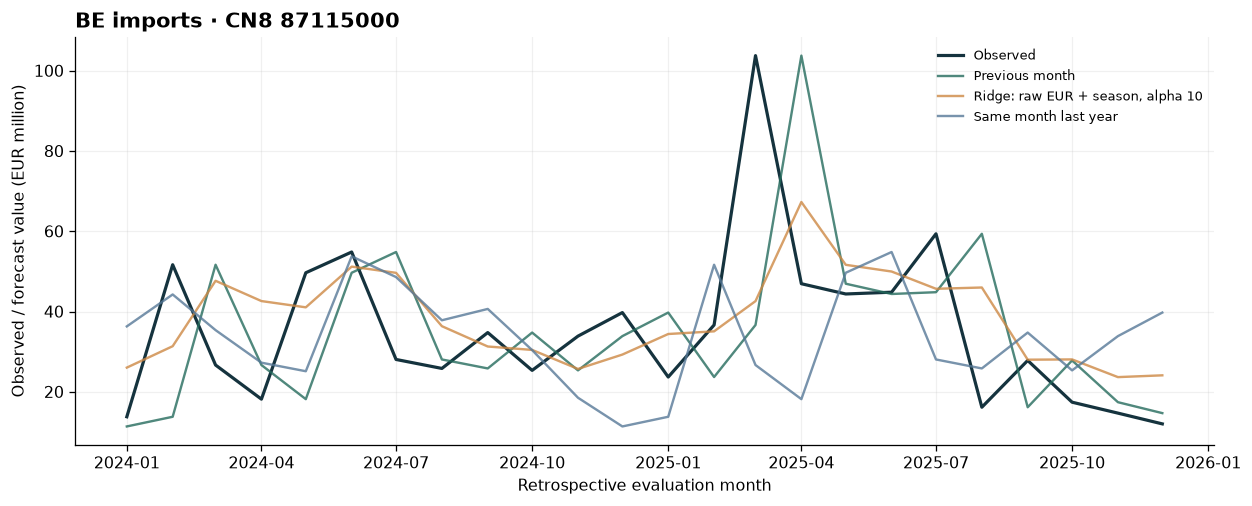

In [5]:
example_predictions = final.loc[
    final.reporter.eq("BE") & final["product"].eq("87115000") & final.flow.eq("1")
]
fig, ax = plt.subplots(figsize=(11, 4.5))
truth = example_predictions.drop_duplicates("month").set_index("month").actual_eur
ax.plot(truth.index, truth / 1e6, color="#15333e", linewidth=2, label="Observed")
for name, group in example_predictions.groupby("model"):
    ax.plot(group.month, group.predicted_eur / 1e6, label=MODEL_LABELS[name], alpha=0.8)
ax.set(
    title="BE imports · CN8 87115000",
    xlabel="Retrospective evaluation month",
    ylabel="Observed / forecast value (EUR million)",
)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

In [6]:
be_large = trade.loc[trade.reporter.eq("BE") & trade["product"].eq("87115000") & trade.flow.eq("1")]
case_months = pd.to_datetime(["2024-03-01", "2025-02-01", "2025-03-01"])
case = be_large.loc[be_large.month.isin(case_months)]
context = case.groupby("month").agg(
    value_eur=("value_eur", "sum"), mass_kg=("net_mass_kg", "sum"), partners=("partner", "nunique")
)
context["EUR_per_kg"] = context.value_eur / context.mass_kg.where(context.mass_kg.gt(0))
display(
    context.assign(value_EUR_m=context.value_eur / 1e6)[
        ["value_EUR_m", "mass_kg", "EUR_per_kg", "partners"]
    ].round(2)
)
# Rank contributors by observed year-on-year value change, retaining missing routes as missing.
annual_case = case.loc[case.month.ne("2025-02-01")]
by_partner = annual_case.pivot(index="partner", columns="month", values="value_eur")
change = by_partner[pd.Timestamp("2025-03-01")] - by_partner[pd.Timestamp("2024-03-01")]
top_partners = change.nlargest(2).index.tolist()
contributions = (
    annual_case.assign(
        partner_group=np.where(
            annual_case.partner.isin(top_partners), annual_case.partner, "Other observed partners"
        )
    )
    .groupby(["partner_group", "month"])
    .value_eur.sum()
    .unstack("month")
)
np.testing.assert_allclose(
    contributions.sum().to_numpy(),
    context.loc[pd.to_datetime(["2024-03-01", "2025-03-01"]), "value_eur"].to_numpy(),
)
contributions["change_EUR"] = contributions.iloc[:, 1] - contributions.iloc[:, 0]
display(
    (contributions / 1e6)
    .rename(
        columns={
            pd.Timestamp("2024-03-01"): "March_2024_EUR_m",
            pd.Timestamp("2025-03-01"): "March_2025_EUR_m",
            "change_EUR": "change_EUR_m",
        }
    )
    .round(2)
)
assert (context.mass_kg > 0).all()

,value_EUR_m,mass_kg,EUR_per_kg,partners
month,,,,
2024-03-01,26.66,577162.0,46.19,10
2025-02-01,36.64,961507.0,38.11,10
2025-03-01,103.75,2823136.0,36.75,13


month,March_2024_EUR_m,March_2025_EUR_m,change_EUR_m
partner_group,,,
Other observed partners,21.57,17.64,-3.93
TH,1.12,48.50,47.37
US,3.97,37.62,33.65


- **The previous month was EUR 36.6m and the previous March EUR 26.7m. Neither input signals the full jump to EUR 103.8m.**
- **Thailand and US partner routes rise by EUR 47.4m and EUR 33.6m versus March 2024; other observed partners decline overall.** These two partners account for the increase.
- **Mass rises from 577,162 to 2,823,136 kg while EUR/kg falls. The value increase mainly reflects more traded mass.** Weight alone does not tell us how many motorcycles moved.
- **Reported partners rise from 10 to 13. I retain this coverage caveat and do not fill absent routes with zeros.**

These checks explain where the miss comes from. They do not show that the jump was predictable beforehand: the model only sees past values and calendar inputs.

## Conclusion

**Raw Ridge improves this retrospective comparison, but misses abrupt changes and does not win every series. I keep it as a candidate alongside the baselines.**

The next test would use a fresh period and only data available at each forecast date. This would check usefulness under publication delays and revisions. Checks for future-data leakage and missing data remain in `tests/`. Next: [statistical prioritization](03_statistical_prioritization.ipynb).